# Parallel perform MC simulation

### Step 1 : Import

In [1]:
import os
import sys
from pathlib import Path

# Let child processes find this Conda environment's numeric DLLs.
os.environ["PATH"] = str(Path(sys.prefix) / "Library" / "bin") + os.pathsep + os.environ["PATH"]
# Child processes only save images; no GUI backend is needed.
os.environ["MPLBACKEND"] = "Agg"

from concurrent.futures import ProcessPoolExecutor
import secrets

In [2]:
from nix2_mc import LatticeNiX2, SpinModelNiX2, MonteCarloNiX2
from nix2_model_builders import *
from nix2_mc import MonteCarloNiX2, KB_MEV_PER_K
from nix2_mc_protocols import run_one_mc, set_temperature_schedule

### Step 2 : Lattice

In [3]:
Lmuc = 7
Nmuc = 4
Na = Nmuc * Lmuc
Nb = 2 * Na
lattice_geometry = "rectangular"

### Step 3 : JKJ3B Model

a model from the PRL 2023 : only consider four parameters ( J1, Kitaev, J3, B )

In [5]:
J1prime = -5
Kitaev = 0.2 * abs(J1prime)
J1mat = exchange_from_hk(J1prime, Kitaev)
J1iso = np.sum(np.diag(J1mat))/3
# Azz = 0.140 # 0.140
Azz = 0.0

B_biquad = 0.15 * J1prime
# J2iso = -0.155
J2iso = 0.0
J2mat = J2iso * np.eye(3)

# J3iso = 2.250 # J3iso should be positive !!!
J3_ratio_list = [0.0, -0.2, -0.3, -0.35, -0.4, -0.45, -0.5, -0.6, -0.8]
# J3mat = J3iso * np.eye(3)

### Step 4 : add M tensor for polarization calculation

In [6]:
# M is in units of 10^-5 e Angstrom; the resulting P is dipole per Ni.
M01 = np.array([[20, 0, 32], [0, 348, -520], [0, 25, 0]], dtype=float)

In [7]:
model_parameters_list = []
for i, J3_ratio in enumerate(J3_ratio_list):
    model_params = {
                        "J1": J1mat,
                        "J2iso": J2iso,
                        "J3": J3_ratio * J1prime,
                        "Azz": Azz,
                        "B_biquad": B_biquad,
                        "B_field": (0.0, 0.0, 0.0)
                    }
    model_parameters_list.append(model_params)

In [8]:
# temperatures
TK_init_list = [70, 50, 19]
TK_final_list = [51, 20, 1]
cooling_method_list = ["linear", "linear", "linear"]
cooling_rate_list = [10, 36, 10]

TK_list = set_temperature_schedule(
    TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
)

In [9]:
num_eq_sweeps = 10000
converg_per_every = 10
num_meas_sweeps = 15000
meas_per_every = 5

### Start Parallel Simulations

In [11]:
num_workers = max(len(model_parameters_list), os.cpu_count() - 2)
with ProcessPoolExecutor(max_workers=num_workers) as pool:
    futures = [
        pool.submit(
            run_one_mc,
            Na, Nb, model_params,
            secrets.randbits(128),
            TK_list,
            num_eq_sweeps, num_meas_sweeps,
            converg_per_every, meas_per_every,
            observables=["E", "P", "M", "Cv"],
            M01=M01,
            geometry=lattice_geometry,
            root="nix2_parallel_simulation_results"
        )
        for model_params in model_parameters_list
    ]

    folders = [future.result() for future in futures]

### Plot

In [17]:
import json
from pathlib import Path
from types import SimpleNamespace
import matplotlib.pyplot as plt
from IPython.display import display
from nix2_mc_output import load_scan_point
from plotting_3d_spins import plot_spin_config
%matplotlib inline

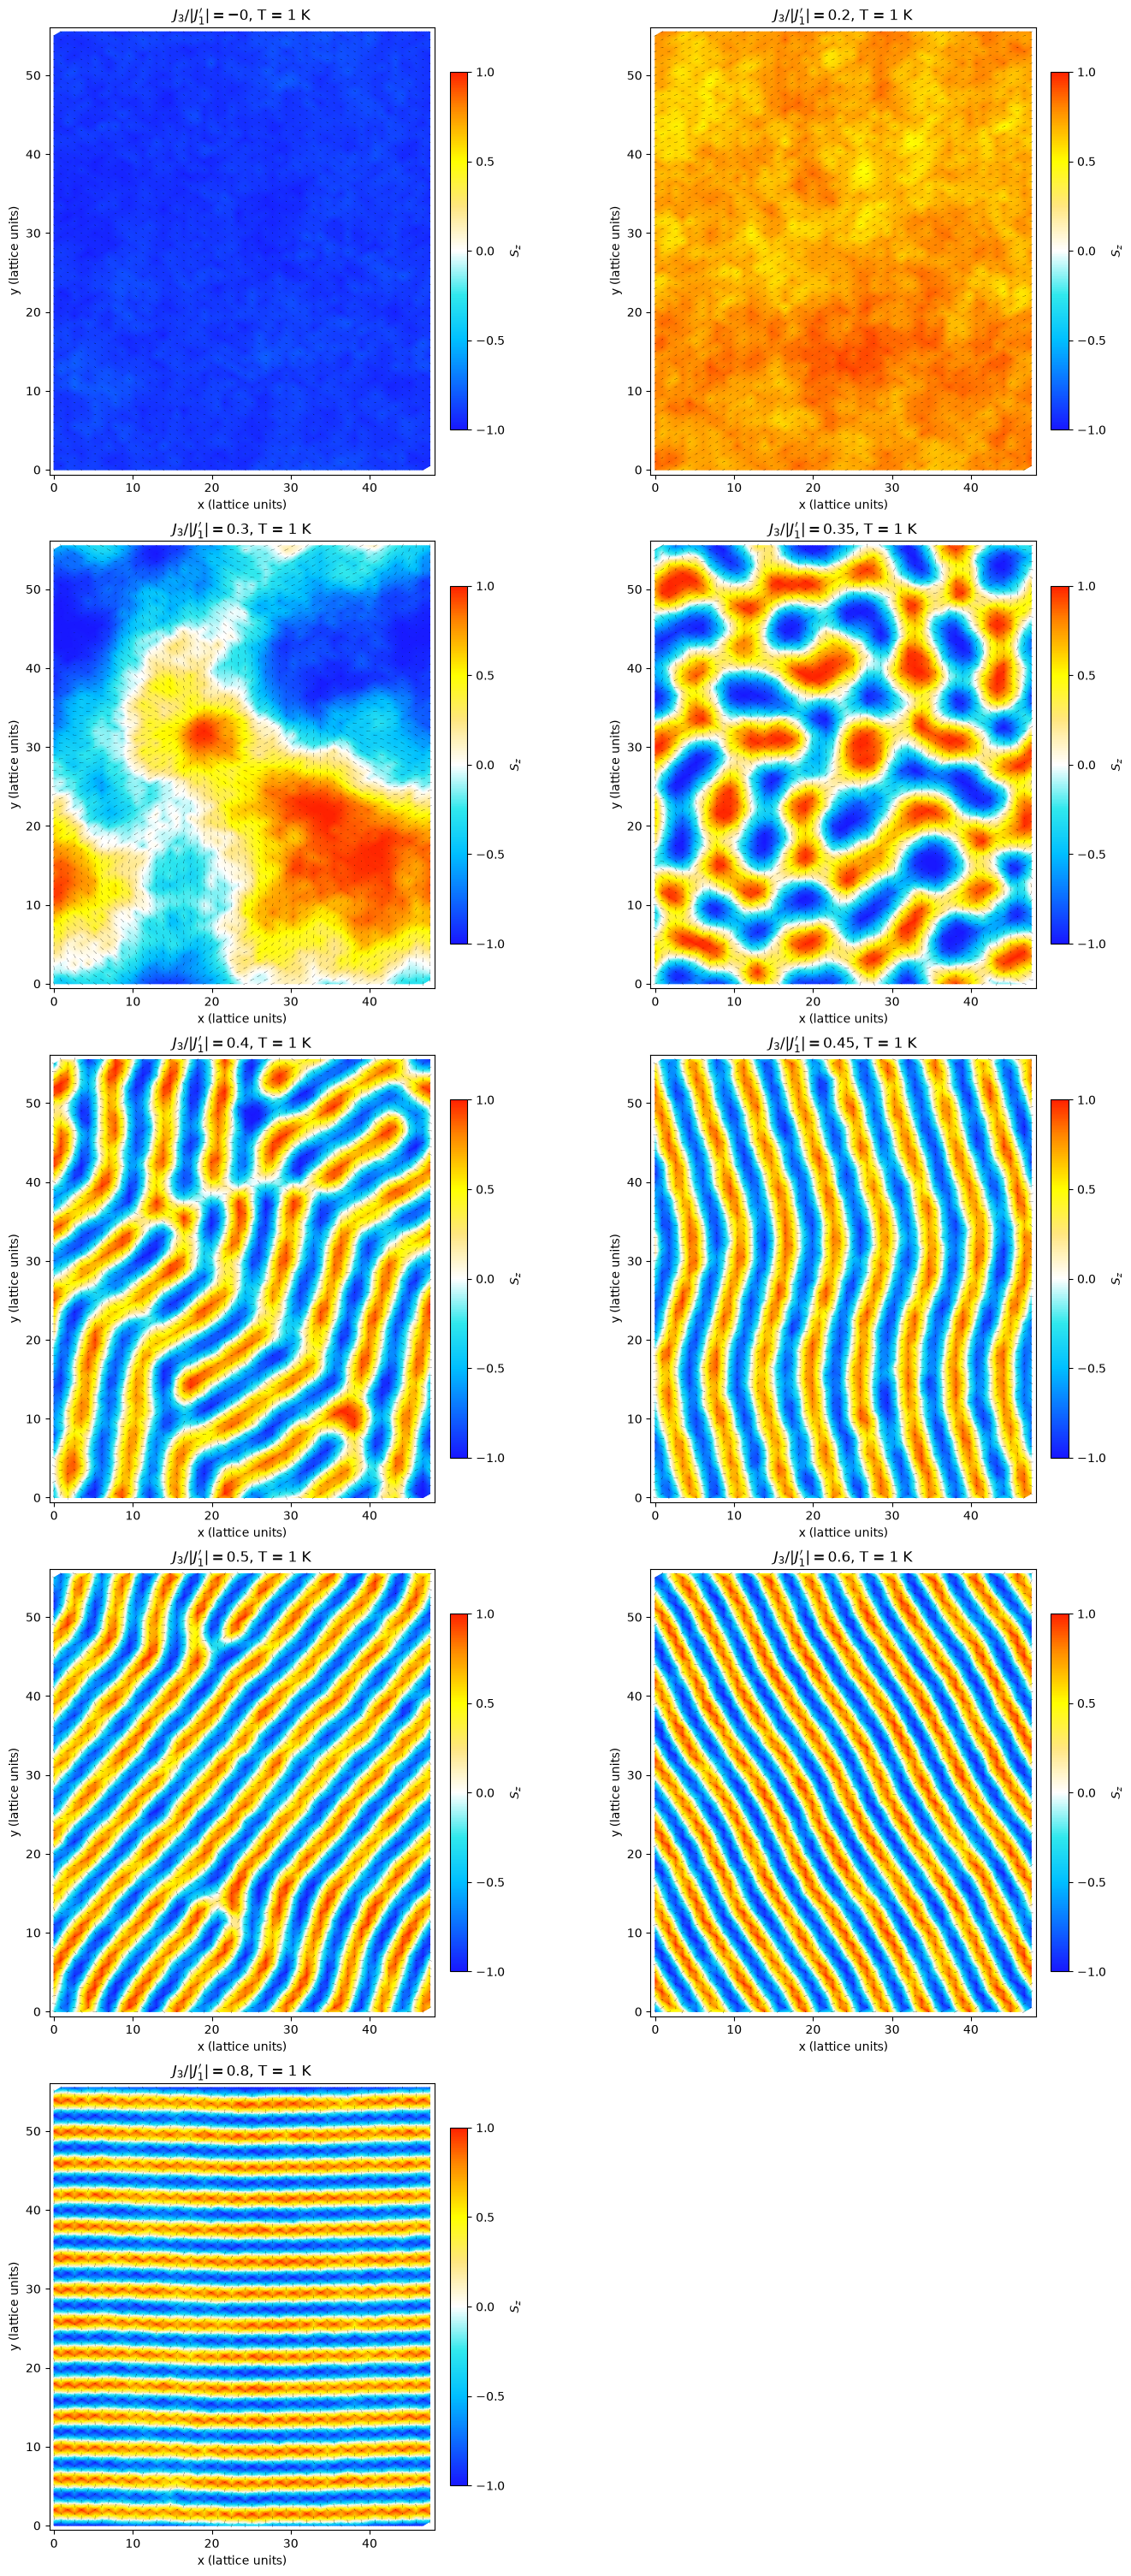

In [19]:
nrows = (len(folders) + 1) // 2
fig, axes = plt.subplots(
    nrows, 2, figsize=(14, 6 * nrows),
    squeeze=False, constrained_layout=True,
)

for ax, folder in zip(axes.flat, folders):
    folder = Path(folder)
    params = json.loads((folder / "parameters.json").read_text())
    final_file = max(
        (folder / "data").glob("*.npz"),
        key=lambda p: int(p.stem),
    )
    point = load_scan_point(final_file)
    lattice = SimpleNamespace(
        get_cartesian_coords=lambda: point["coordinates"]
    )

    ratio = params["J3"] / abs(J1prime)
    temperature = float(point["parameters"]["temperature_K"])

    plot_spin_config(
        point["spins"], lattice, ax=ax, flag_show=False,
        title=rf"$J_3/|J_1^\prime| = {ratio:g}$, T = {temperature:g} K",
    )

for ax in list(axes.flat)[len(folders):]:
    ax.set_visible(False)

display(fig)
plt.close(fig)

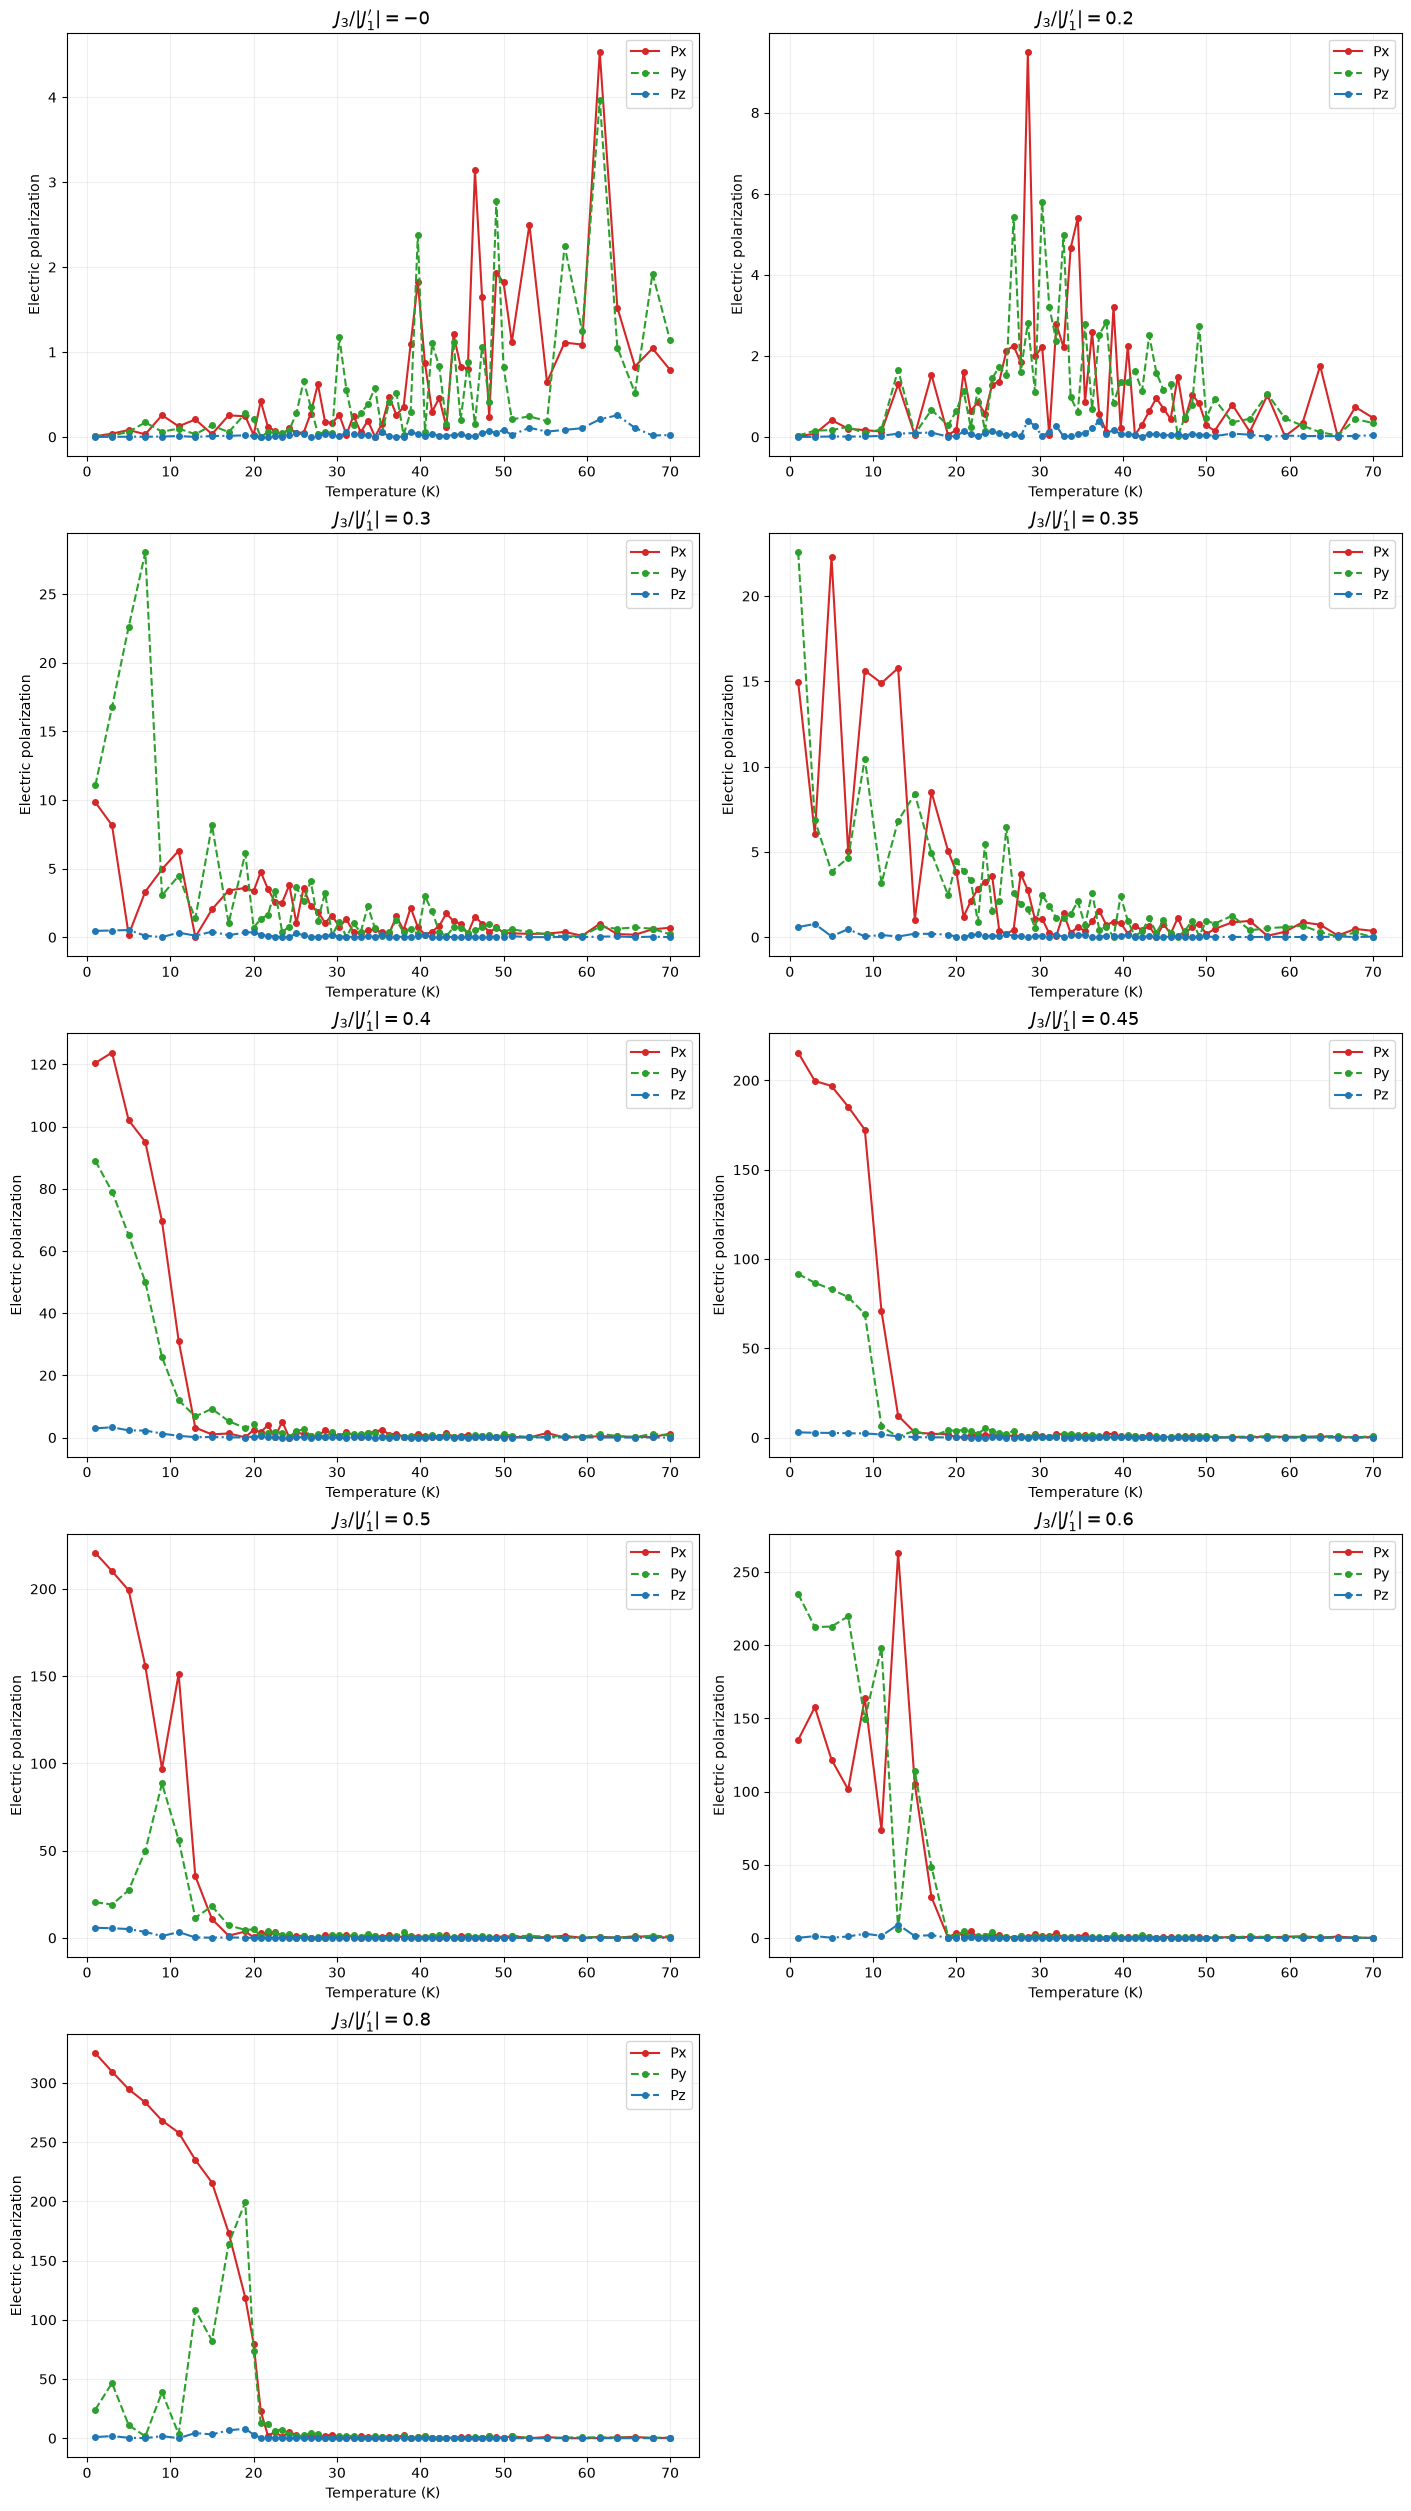

In [21]:
from plotting_3d_spins import plot_curves

nrows = (len(folders) + 1) // 2
fig, axes = plt.subplots(
    nrows, 2, figsize=(14, 5 * nrows),
    squeeze=False, constrained_layout=True,
)

for ax, folder in zip(axes.flat, folders):
    folder = Path(folder)
    params = json.loads((folder / "parameters.json").read_text())
    rows = []

    for path in sorted((folder / "data").glob("*.npz")):
        with np.load(path) as data:
            rows.append([
                float(data["parameter__temperature_K"]),
                *data["observable__electric_polarization_mean"],
            ])

    curve = np.asarray(rows)
    ratio = params["J3"] / abs(J1prime)

    plot_curves(
        curve[:, 0], abs(curve[:, 1:]).T, ax=ax,
        xlabel="Temperature (K)", ylabel1="Electric polarization",
        label1=["Px", "Py", "Pz"],
        colors=(["tab:red", "tab:green", "tab:blue"], "black"),
        title=rf"$J_3/|J_1^\prime| = {ratio:g}$",
    )

for ax in list(axes.flat)[len(folders):]:
    ax.set_visible(False)

plt.show()